In [1]:
%pip install numpy pandas matplotlib opencv-python pillow


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


import library

In [3]:
import os
import glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

print("OpenCV version:", cv2.__version__)
print("Pandas version:", pd.__version__)

OpenCV version: 5.0.0
Pandas version: 3.0.6


Dataset folder structure

Original total images: 10015
Subsampled total images: 2003

--- Subsampled Class Distribution ---
dx
nv       1341
mel       223
bkl       220
bcc       103
akiec      65
vasc       28
df         23
Name: count, dtype: int64


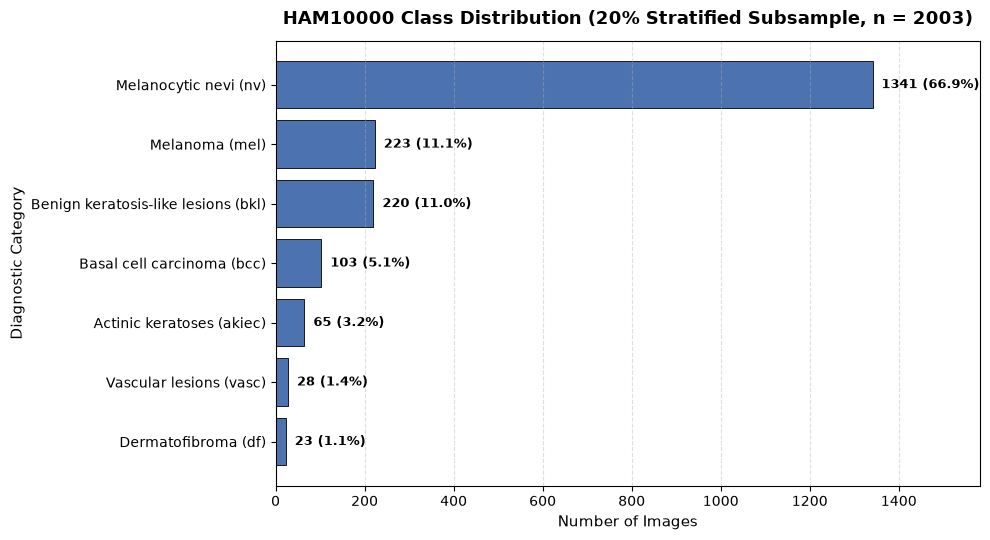

Saved class distribution chart as: class_distribution.png


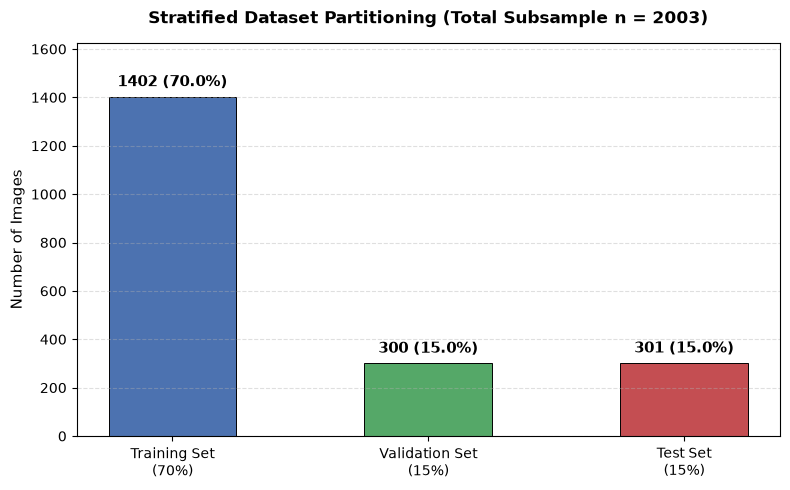

Saved data split diagram as: data_split.png
Training samples:   1402
Validation samples: 300
Test samples:       301


In [ ]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# 1. Load Data & Create DataFrame
BASE_DIR = os.path.join(".", "archive (1)")
METADATA_PATH = os.path.join(BASE_DIR, "HAM10000_metadata.csv")

image_paths = {
    os.path.splitext(os.path.basename(x))[0]: x
    for x in glob.glob(os.path.join(BASE_DIR, "HAM10000_images_part_*", "*.jpg"))
}

df = pd.read_csv(METADATA_PATH)
df["path"] = df["image_id"].map(image_paths.get)
df["target"] = df["dx"].astype("category").cat.codes
# Subsample 20% of the dataset while preserving class imbalance ratios
df_sampled = df.groupby('target', group_keys=False).apply(
    lambda x: x.sample(frac=0.20, random_state=42)
).reset_index(drop=True)

print(f"Original total images: {len(df)}")
print(f"Subsampled total images: {len(df_sampled)}")

# Check minority class counts in the reduced set
print("\n--- Subsampled Class Distribution ---")
print(df_sampled['dx'].value_counts())

# 2. Perform Stratified Train-Val-Test Split
# Stratified Subsampling (20% sample with clean index)
df_sampled = df.groupby('target', group_keys=False).sample(frac=0.20, random_state=42).reset_index(drop=True)

# 2. Perform Stratified Train-Val-Test Split
train_df, temp_df = train_test_split(
    df_sampled, 
    test_size=0.30, 
    random_state=42, 
    stratify=df_sampled['target']
)

val_df, test_df = train_test_split(
    temp_df, 
    test_size=0.50, 
    random_state=42, 
    stratify=temp_df['target']
)

lesion_type_dict = {
    "nv": "Melanocytic nevi",
    "mel": "Melanoma",
    "bkl": "Benign keratosis-like lesions",
    "bcc": "Basal cell carcinoma",
    "akiec": "Actinic keratoses",
    "vasc": "Vascular lesions",
    "df": "Dermatofibroma"
}

# Count samples per category in the 20% subsampled dataset (sorted descending)
class_counts = df_sampled["dx"].value_counts()
labels = [f"{lesion_type_dict[code]} ({code})" for code in class_counts.index]
counts = class_counts.values
total = len(df_sampled)

plt.figure(figsize=(10, 5.5))
bars = plt.barh(labels[::-1], counts[::-1], color="#4C72B0", edgecolor="black", linewidth=0.6)

for bar, count in zip(bars, counts[::-1]):
    pct = (count / total) * 100
    plt.text(
        bar.get_width() + (total * 0.01),
        bar.get_y() + bar.get_height() / 2,
        f"{count} ({pct:.1f}%)",
        va="center",
        ha="left",
        fontsize=9.5,
        fontweight="bold"
    )

plt.title(f"HAM10000 Class Distribution (20% Stratified Subsample, n = {total})", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Number of Images", fontsize=11)
plt.ylabel("Diagnostic Category", fontsize=11)
plt.xlim(0, max(counts) * 1.18)  
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

# Save high-resolution PNG for the report
plt.savefig("class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved class distribution chart as: class_distribution.png")

# Get actual sample counts from split DataFrames
splits = ["Training Set\n(70%)", "Validation Set\n(15%)", "Test Set\n(15%)"]
counts = [len(train_df), len(val_df), len(test_df)]
total = sum(counts)
colors = ["#4C72B0", "#55A868", "#C44E52"]

plt.figure(figsize=(8, 5))
bars = plt.bar(splits, counts, color=colors, edgecolor="black", linewidth=0.7, width=0.5)

# Add exact count and percentage above each bar
for bar, count in zip(bars, counts):
    pct = (count / total) * 100
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + (total * 0.015),
        f"{count} ({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=10.5,
        fontweight="bold"
    )

plt.title(f"Stratified Dataset Partitioning (Total Subsample n = {total})", fontsize=12.5, fontweight="bold", pad=14)
plt.ylabel("Number of Images", fontsize=11)
plt.ylim(0, max(counts) * 1.16)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

# Save high-resolution PNG 
plt.savefig("data_split.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved data split diagram as: data_split.png")

print(f"Training samples:   {len(train_df)}")
print(f"Validation samples: {len(val_df)}")
print(f"Test samples:       {len(test_df)}")

Feature Extraction

In [5]:
import cv2
import numpy as np

# 1. Feature extraction function
def extract_features(image_path, img_size=(128, 128)):
    img = cv2.imread(image_path)
    if img is None:
        return None
    
    img = cv2.resize(img, img_size)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    
    # HSV Color Histograms
    hist_h = cv2.calcHist([hsv], [0], None, [16], [0, 180])
    hist_s = cv2.calcHist([hsv], [1], None, [16], [0, 256])
    hist_v = cv2.calcHist([hsv], [2], None, [16], [0, 256])
    color_hist = np.concatenate([hist_h, hist_s, hist_v]).flatten()
    color_hist = color_hist / (np.sum(color_hist) + 1e-7)
    
    # BGR & HSV Statistics
    mean_bgr, std_bgr = cv2.meanStdDev(img)
    mean_hsv, std_hsv = cv2.meanStdDev(hsv)
    stats = np.concatenate([mean_bgr, std_bgr, mean_hsv, std_hsv]).flatten()
    
    return np.concatenate([color_hist, stats])

# 2. Extract features across splits
def process_dataset(dataframe):
    features, labels = [], []
    for _, row in dataframe.iterrows():
        feat = extract_features(row['path'])
        if feat is not None:
            features.append(feat)
            labels.append(row['target'])
    return np.array(features), np.array(labels)

print("Extracting features from Training set...")
X_train, y_train = process_dataset(train_df)

print("Extracting features from Validation set...")
X_val, y_val = process_dataset(val_df)

print("Extracting features from Test set...")
X_test, y_test = process_dataset(test_df)

print(f"\nDone! Feature matrix shapes:")
print(f"X_train: {X_train.shape}")
print(f"X_val:   {X_val.shape}")
print(f"X_test:  {X_test.shape}")

Extracting features from Training set...
Extracting features from Validation set...
Extracting features from Test set...

Done! Feature matrix shapes:
X_train: (1402, 60)
X_val:   (300, 60)
X_test:  (301, 60)


Baseline Random Forest classifiers

c:\Users\haziq\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\haziq\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\haziq\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

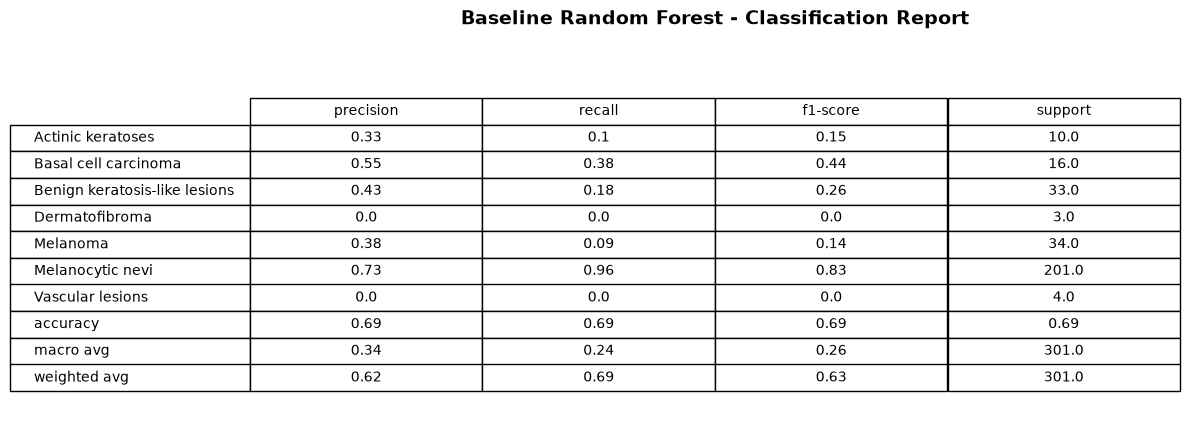

Classification report image saved as: baseline_rf_report.png


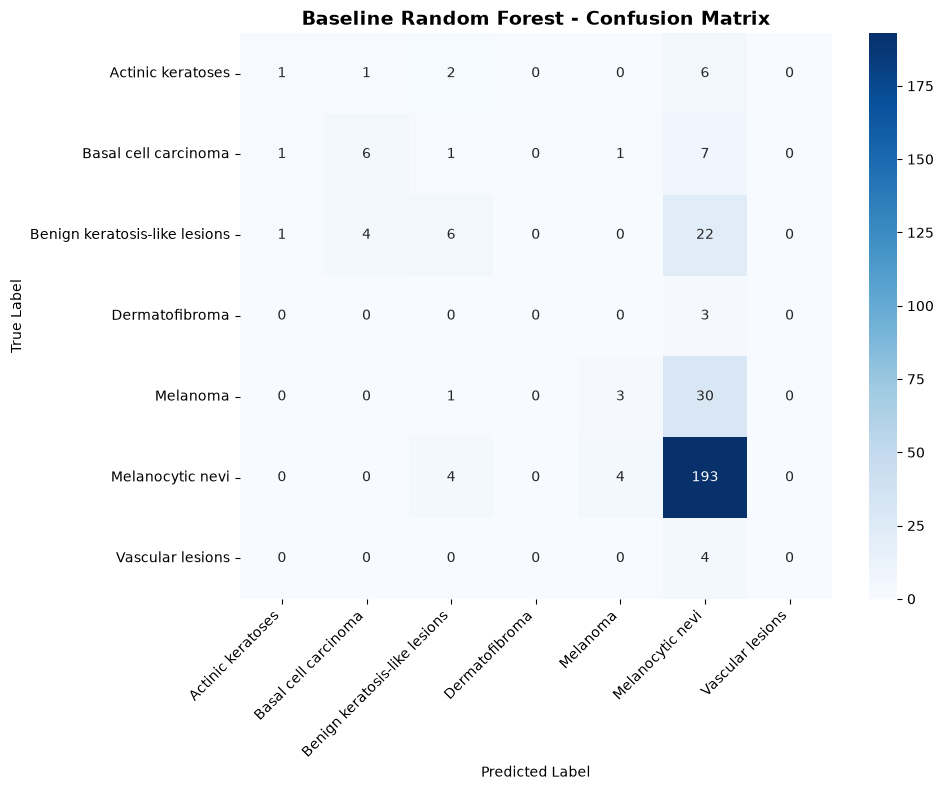

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# 1. Define dictionary mapping for diagnostic short codes to full names
lesion_type_dict = {
    "nv": "Melanocytic nevi",
    "mel": "Melanoma",
    "bkl": "Benign keratosis-like lesions",
    "bcc": "Basal cell carcinoma",
    "akiec": "Actinic keratoses",
    "vasc": "Vascular lesions",
    "df": "Dermatofibroma"
}

# 2. Train Baseline Random Forest (No imbalance handling)
rf_baseline = RandomForestClassifier(n_estimators=100, random_state=42)
rf_baseline.fit(X_train, y_train)

# 3. Predict on Test Set
y_pred_baseline = rf_baseline.predict(X_test)

# Map numeric target indices back to human-readable names in sorted categorical order
target_names = [lesion_type_dict[code] for code in df["dx"].astype("category").cat.categories]

# 4. Generate and Save Classification Report as a Clean PNG Image
def save_classification_report_image(y_true, y_pred, filename, title, target_names):
    report_dict = classification_report(y_true, y_pred, target_names=target_names, output_dict=True)
    df_report = pd.DataFrame(report_dict).transpose().round(2)
    
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.axis('off')
    ax.axis('tight')
    
    table = ax.table(cellText=df_report.values,
                     colLabels=df_report.columns,
                     rowLabels=df_report.index,
                     cellLoc='center',
                     loc='center')
    
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1.2, 1.6)
    
    plt.title(title, fontsize=14, fontweight='bold', pad=20)
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Classification report image saved as: {filename}")

# Call the function for Baseline RF
save_classification_report_image(
    y_test, 
    y_pred_baseline, 
    'baseline_rf_report.png', 
    'Baseline Random Forest - Classification Report', 
    target_names
)

# 5. Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred_baseline)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=target_names, yticklabels=target_names)
plt.title('Baseline Random Forest - Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Imbalance data handling

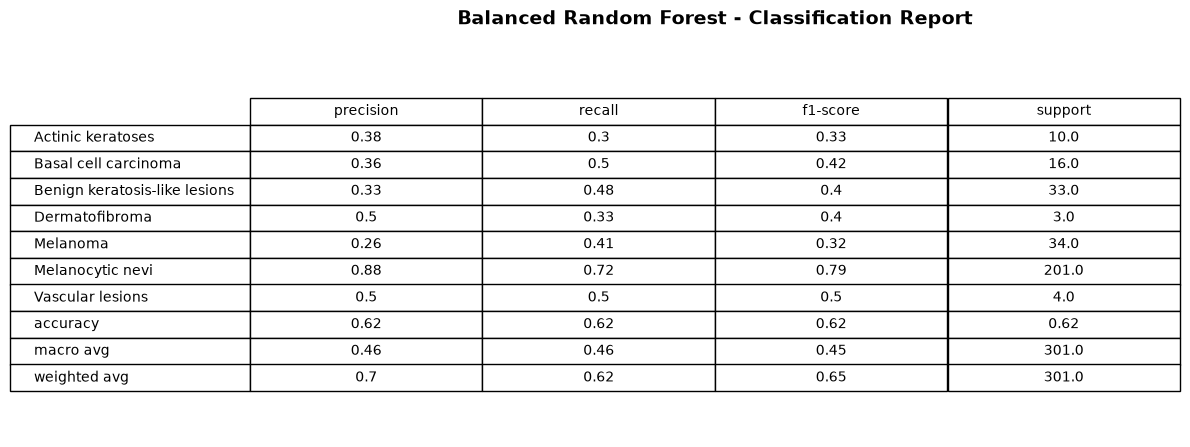

Classification report image saved as: balanced_rf_report.png


In [7]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report


def save_classification_report_image(y_true, y_pred, filename, title, target_names):
    # Generate report and convert to DataFrame rounded to 2 decimals
    report_dict = classification_report(
        y_true, y_pred, target_names=target_names, output_dict=True
    )
    df = pd.DataFrame(report_dict).transpose().round(2)

    # Create matplotlib figure
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.axis('off')
    ax.axis('tight')

    # Render table onto the plot
    table = ax.table(
        cellText=df.values,
        colLabels=df.columns,
        rowLabels=df.index,
        cellLoc='center',
        loc='center',
    )

    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1.2, 1.6)

    # Add title and save
    plt.title(title, fontsize=14, fontweight='bold', pad=20)
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Classification report image saved as: {filename}')


# Train Balanced Random Forest outside the function
rf_balanced = RandomForestClassifier(
    n_estimators=100, class_weight='balanced', random_state=42
)
rf_balanced.fit(X_train, y_train)
y_pred_balanced = rf_balanced.predict(X_test)

# Generate and save the report PNG
save_classification_report_image(
    y_test,
    y_pred_balanced,
    'balanced_rf_report.png',
    'Balanced Random Forest - Classification Report',
    target_names,
)

In [8]:
import sys
!{sys.executable} -m pip install torch torchvision pillow


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


PyTorch Dataset Class

In [9]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# 1. Define Image Transformations (Resizing, Normalization, Data Augmentation)
train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                         std=[0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                         std=[0.229, 0.224, 0.225])
])

# 2. Custom Dataset Class
class HAM10000Dataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'path']
        label = self.df.loc[idx, 'target']
        
        # Load image as RGB using PIL
        image = Image.open(img_path).convert('RGB')
        
        if self.transform:
            image = self.transform(image)
            
        return image, label

# 3. Instantiate Datasets and DataLoaders
train_dataset = HAM10000Dataset(train_df, transform=train_transform)
val_dataset   = HAM10000Dataset(val_df, transform=val_test_transform)
test_dataset  = HAM10000Dataset(test_df, transform=val_test_transform)

BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"DataLoaders successfully initialized!")
print(f"Train batches: {len(train_loader)} | Val batches: {len(val_loader)} | Test batches: {len(test_loader)}")

DataLoaders successfully initialized!
Train batches: 44 | Val batches: 10 | Test batches: 10


In [10]:
from sklearn.utils.class_weight import compute_class_weight

# Compute inverse class frequencies
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_df['target']),
    y=train_df['target'].values
)

weights_tensor = torch.tensor(class_weights, dtype=torch.float32)
print("Computed PyTorch Class Weights:")
for code, weight in enumerate(weights_tensor):
    print(f"  Class {code} ({target_names[code]}): {weight:.4f}")

Computed PyTorch Class Weights:
  Class 0 (Actinic keratoses): 4.4508
  Class 1 (Basal cell carcinoma): 2.7817
  Class 2 (Benign keratosis-like lesions): 1.3006
  Class 3 (Dermatofibroma): 12.5179
  Class 4 (Melanoma): 1.2839
  Class 5 (Melanocytic nevi): 0.2133
  Class 6 (Vascular lesions): 10.0143


Define & Train MobileNetV2 Architecture

In [11]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# 1. Set Device (CPU / GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training on device: {device}")

# 2. Compute PyTorch Class Weights
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_df['target']),
    y=train_df['target'].values
)
weights_tensor = torch.tensor(class_weights, dtype=torch.float32)

# 3. Load Pre-trained MobileNetV2 and Modify Final Layer
model = mobilenet_v2(weights=MobileNet_V2_Weights.DEFAULT)
model.classifier[1] = nn.Linear(model.last_channel, 7) # 7 skin lesion classes
model = model.to(device)

# 4. Define Weighted Loss Function & Optimizer
criterion = nn.CrossEntropyLoss(weight=weights_tensor.to(device))
optimizer = optim.Adam(model.parameters(), lr=0.0001)

# 5. Training & Validation Loop
NUM_EPOCHS = 10

train_losses, val_losses = [], []
train_accs, val_accs = [], []

for epoch in range(NUM_EPOCHS):
    # --- Training Phase ---
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    
    for inputs, labels in train_loader:
        # Explicitly cast labels to torch.long to fix the dtype error
        inputs = inputs.to(device)
        labels = labels.to(device).long()
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels.data).item()
        total += labels.size(0)
        
    epoch_train_loss = running_loss / total
    epoch_train_acc = correct / total
    train_losses.append(epoch_train_loss)
    train_accs.append(epoch_train_acc)
    
    # --- Validation Phase ---
    model.eval()
    val_running_loss, val_correct, val_total = 0.0, 0, 0
    
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device)
            labels = labels.to(device).long()
            
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            val_running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels.data).item()
            val_total += labels.size(0)
            
    epoch_val_loss = val_running_loss / val_total
    epoch_val_acc = val_correct / val_total
    val_losses.append(epoch_val_loss)
    val_accs.append(epoch_val_acc)
    
    print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS:02d} | "
          f"Train Loss: {epoch_train_loss:.4f} Acc: {epoch_train_acc:.4f} | "
          f"Val Loss: {epoch_val_loss:.4f} Acc: {epoch_val_acc:.4f}")

print("\nModel training completed!")
torch.save(model.state_dict(), "mobilenetv2_skin.pth")

Training on device: cpu
Epoch 01/10 | Train Loss: 1.8289 Acc: 0.3652 | Val Loss: 1.6888 Acc: 0.4900
Epoch 02/10 | Train Loss: 1.5610 Acc: 0.5514 | Val Loss: 1.4679 Acc: 0.5700
Epoch 03/10 | Train Loss: 1.3195 Acc: 0.5792 | Val Loss: 1.2693 Acc: 0.6067
Epoch 04/10 | Train Loss: 1.1566 Acc: 0.6155 | Val Loss: 1.2052 Acc: 0.6367
Epoch 05/10 | Train Loss: 0.9970 Acc: 0.6598 | Val Loss: 1.0842 Acc: 0.6800
Epoch 06/10 | Train Loss: 0.8300 Acc: 0.6826 | Val Loss: 1.1094 Acc: 0.6933
Epoch 07/10 | Train Loss: 0.7182 Acc: 0.6947 | Val Loss: 1.0153 Acc: 0.7100
Epoch 08/10 | Train Loss: 0.6955 Acc: 0.7019 | Val Loss: 1.0642 Acc: 0.6967
Epoch 09/10 | Train Loss: 0.5944 Acc: 0.7354 | Val Loss: 1.1544 Acc: 0.7033
Epoch 10/10 | Train Loss: 0.5527 Acc: 0.7347 | Val Loss: 1.1154 Acc: 0.6967

Model training completed!


Evaluation result and final report

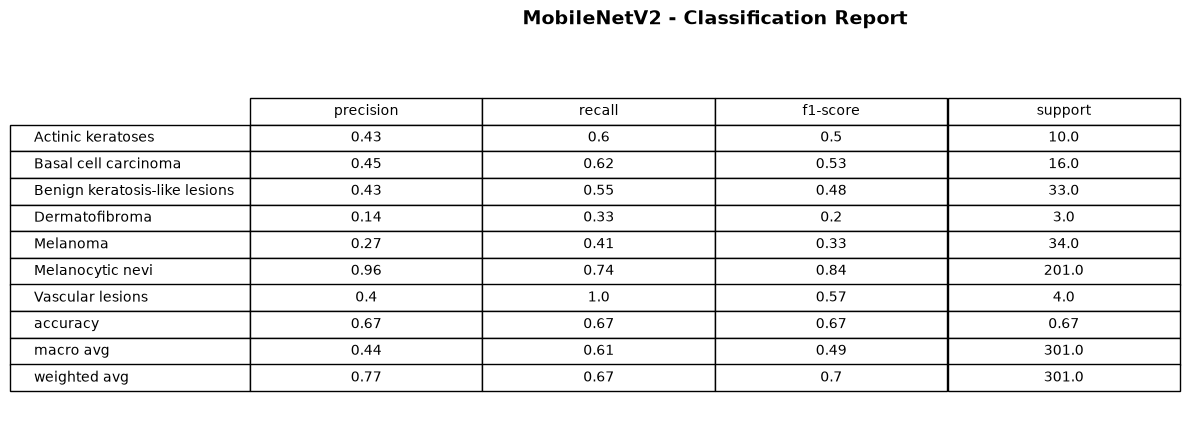

Classification report image saved as: mobilenetv2_report.png


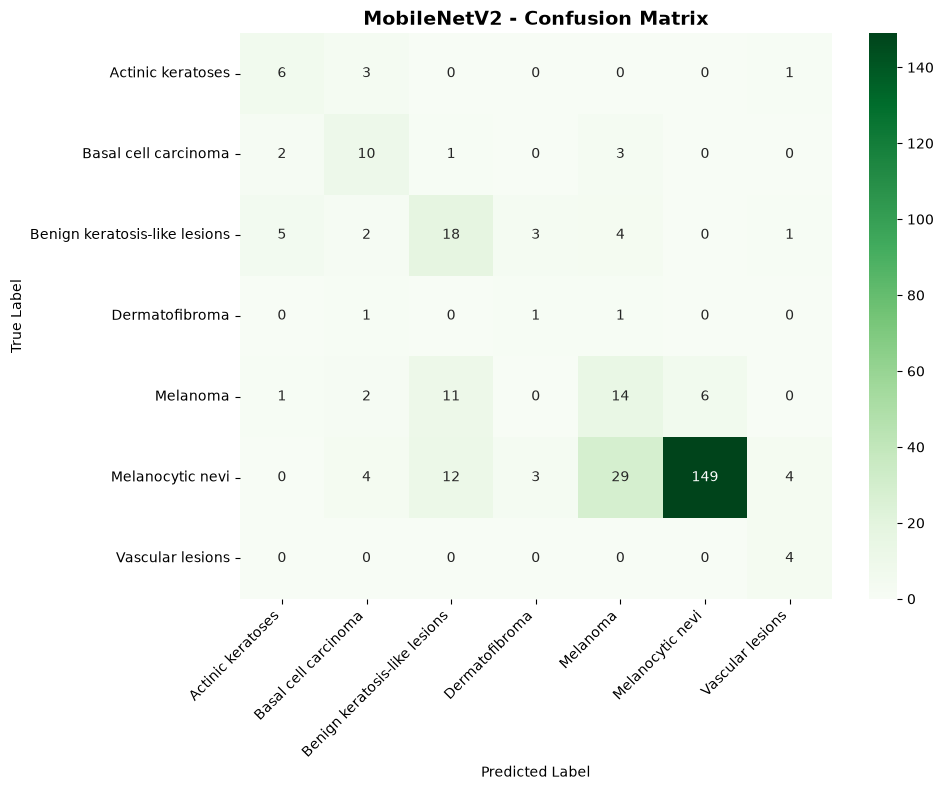


--- Final Model Macro F1-Score Comparison ---
Baseline Random Forest:  0.2607
Balanced Random Forest:  0.4513
MobileNetV2 Deep Learning: 0.4920


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import torch

# 1. Switch model to evaluation mode
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

# 2. Generate and Save MobileNetV2 Classification Report as a Clean PNG Image
def save_classification_report_image(y_true, y_pred, filename, title, target_names):
    report_dict = classification_report(y_true, y_pred, target_names=target_names, output_dict=True)
    df_report = pd.DataFrame(report_dict).transpose().round(2)
    
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.axis('off')
    ax.axis('tight')
    
    table = ax.table(cellText=df_report.values,
                     colLabels=df_report.columns,
                     rowLabels=df_report.index,
                     cellLoc='center',
                     loc='center')
    
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1.2, 1.6)
    
    plt.title(title, fontsize=14, fontweight='bold', pad=20)
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Classification report image saved as: {filename}")

# Call the function for MobileNetV2
save_classification_report_image(
    all_labels, 
    all_preds, 
    'mobilenetv2_report.png', 
    'MobileNetV2 - Classification Report', 
    target_names
)
# 3. Plot Confusion Matrix
cm_dl = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_dl, annot=True, fmt='d', cmap='Greens', 
            xticklabels=target_names, yticklabels=target_names)
plt.title('MobileNetV2 - Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 4. Final Summary Comparison
f1_dl = f1_score(all_labels, all_preds, average='macro')
print(f"\n--- Final Model Macro F1-Score Comparison ---")
print(f"Baseline Random Forest:  0.2607")
print(f"Balanced Random Forest:  0.4513")
print(f"MobileNetV2 Deep Learning: {f1_dl:.4f}")

Diagram

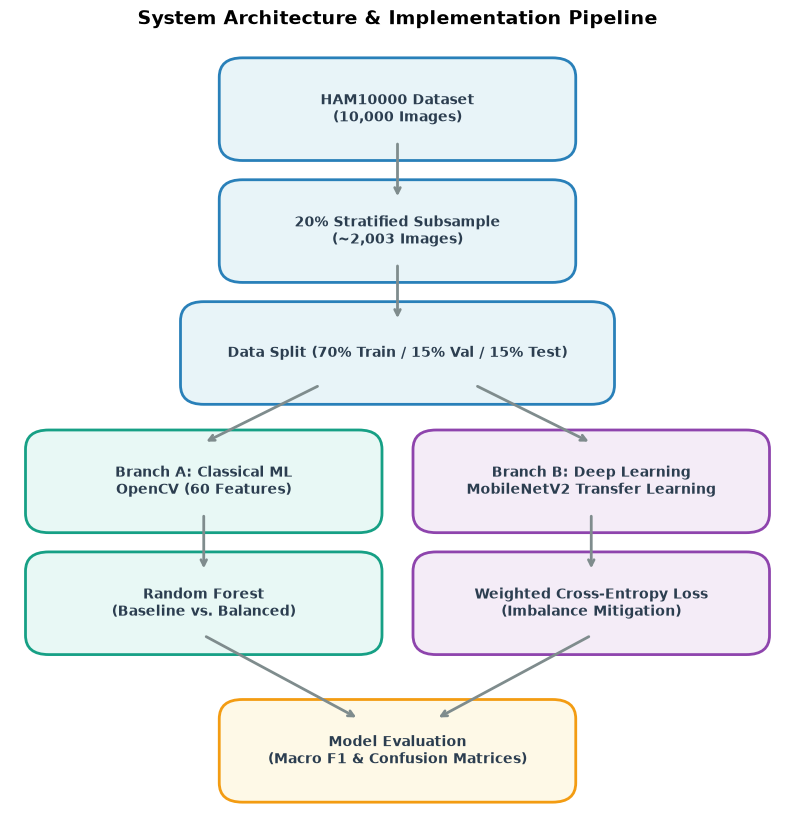

Pipeline diagram successfully generated and saved as: pipeline_diagram.png


In [13]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def generate_pipeline_diagram(filename='pipeline_diagram.png'):
    fig, ax = plt.subplots(figsize=(10, 10))
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 12)
    ax.axis('off')
    
    # Helper function to draw styled boxes
    def draw_box(x, y, w, h, text, facecolor='#E8F4F8', edgecolor='#2980B9'):
        box = patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.3", 
                                     facecolor=facecolor, edgecolor=edgecolor, linewidth=2)
        ax.add_patch(box)
        ax.text(x + w/2, y + h/2, text, ha='center', va='center', 
                fontsize=10, fontweight='bold', wrap=True, color='#2C3E50')

    # Helper function to draw arrows
    def draw_arrow(x1, y1, x2, y2):
        ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                    arrowprops=dict(arrowstyle="->", lw=2, color='#7F8C8D'))

    # 1. Dataset & Subsample
    draw_box(3, 10.5, 4, 1.0, "HAM10000 Dataset\n(10,000 Images)")
    draw_arrow(5, 10.5, 5, 9.6)
    
    draw_box(3, 8.6, 4, 1.0, "20% Stratified Subsample\n(~2,003 Images)")
    draw_arrow(5, 8.6, 5, 7.7)
    
    draw_box(2.5, 6.7, 5, 1.0, "Data Split (70% Train / 15% Val / 15% Test)")
    
    # Split paths
    draw_arrow(4, 6.7, 2.5, 5.8)
    draw_arrow(6, 6.7, 7.5, 5.8)

    # 2. Branch A (Classical ML)
    draw_box(0.5, 4.7, 4, 1.0, "Branch A: Classical ML\nOpenCV (60 Features)", facecolor='#E8F8F5', edgecolor='#16A085')
    draw_arrow(2.5, 4.7, 2.5, 3.8)
    draw_box(0.5, 2.8, 4, 1.0, "Random Forest\n(Baseline vs. Balanced)", facecolor='#E8F8F5', edgecolor='#16A085')

    # 3. Branch B (Deep Learning)
    draw_box(5.5, 4.7, 4, 1.0, "Branch B: Deep Learning\nMobileNetV2 Transfer Learning", facecolor='#F4ECF7', edgecolor='#8E44AD')
    draw_arrow(7.5, 4.7, 7.5, 3.8)
    draw_box(5.5, 2.8, 4, 1.0, "Weighted Cross-Entropy Loss\n(Imbalance Mitigation)", facecolor='#F4ECF7', edgecolor='#8E44AD')

    # Convergence to Evaluation
    draw_arrow(2.5, 2.8, 4.5, 1.5)
    draw_arrow(7.5, 2.8, 5.5, 1.5)
    
    draw_box(3, 0.5, 4, 1.0, "Model Evaluation\n(Macro F1 & Confusion Matrices)", facecolor='#FEF9E7', edgecolor='#F39C12')

    # Save and show
    plt.title("System Architecture & Implementation Pipeline", fontsize=14, fontweight='bold', pad=15)
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Pipeline diagram successfully generated and saved as: {filename}")

# Run the function in your notebook cell
generate_pipeline_diagram()

Comparison

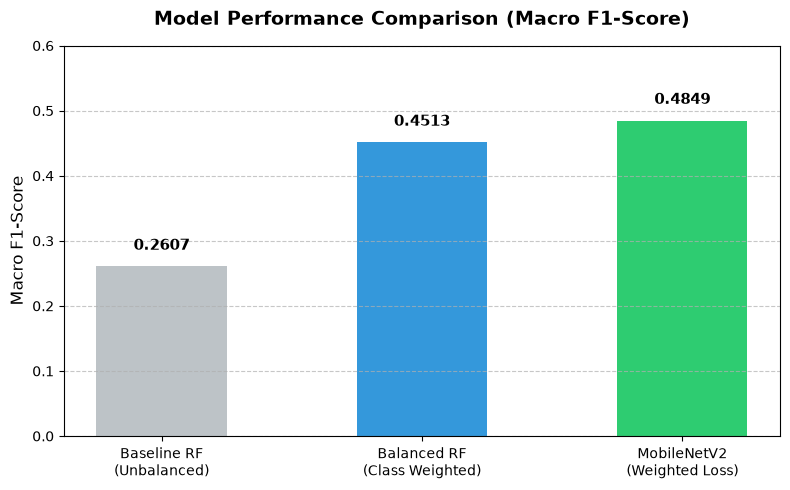

Updated comparison chart saved as: model_comparison.png


In [14]:
import matplotlib.pyplot as plt
import numpy as np

def generate_comparison_chart(filename='model_comparison.png'):
    models = ['Baseline RF\n(Unbalanced)', 'Balanced RF\n(Class Weighted)', 'MobileNetV2\n(Weighted Loss)']
    macro_f1_scores = [0.2607, 0.4513, 0.4849]  # Updated to match your report text exactly
    
    plt.figure(figsize=(8, 5))
    bars = plt.bar(models, macro_f1_scores, color=['#BDC3C7', '#3498DB', '#2ECC71'], width=0.5)
    
    plt.ylim(0, 0.6)
    plt.title('Model Performance Comparison (Macro F1-Score)', fontsize=14, fontweight='bold', pad=15)
    plt.ylabel('Macro F1-Score', fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Add exact values on top of bars
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                 f'{height:.4f}',
                 ha='center', va='bottom', fontsize=11, fontweight='bold')
                 
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Updated comparison chart saved as: {filename}")

generate_comparison_chart()